In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Load the dataset
df = pd.read_csv("dataset_cleaned.csv")

# Define the target and the 21 static code metrics used as features
target = "defect"

features = [
    "cbo", "wmc", "dit", "rfc", "lcom", "totalMethods",
    "totalFields", "nosi", "loc", "returnQty", "loopQty",
    "comparisonsQty", "tryCatchQty", "parenthesizedExpsQty",
    "stringLiteralsQty", "numbersQty", "assignmentsQty",
    "mathOperationsQty", "variablesQty", "maxNestedBlocks",
    "uniqueWordsQty"
]


# Check for missing identifiers, target values, or feature values
print("Dataset shape:", df.shape)
print("Missing SHA values:", df["SHA"].isna().sum())
print("Missing target values:", df[target].isna().sum())
print("Missing feature values:", df[features].isna().sum().sum())
print("\nTarget distribution:")
print(df[target].value_counts().sort_index())

# Confirm that the target contains only the expected binary labels
if df[target].isna().any() or not set(df[target].unique()).issubset({0, 1}):
    raise ValueError("The target must contain only 0 and 1, with no missing values.")

# log1p requires non-negative feature values
if (df[features] < 0).any().any():
    raise ValueError("Negative feature values were found; review them before log1p.")

Dataset shape: (5766, 23)
Missing SHA values: 0
Missing target values: 0
Missing feature values: 0

Target distribution:
defect
0    2922
1    2844
Name: count, dtype: int64


In [4]:
# Create a group ID using the first 40 characters of SHA
df["group_id"] = df["SHA"].astype(str).str[:40]

# Check whether each group contains exactly two rows with both target labels
group_check = df.groupby("group_id").agg(
    row_count=(target, "size"),
    unique_labels=(target, "nunique")
)

print("Number of groups:", len(group_check))
print("\nRows per group:")
print(group_check["row_count"].value_counts().sort_index())

invalid_groups = group_check[
    (group_check["row_count"] != 2) |
    (group_check["unique_labels"] != 2)
]

print("Invalid groups:", len(invalid_groups))

# Stop if the assumed grouping rule does not hold for the whole dataset
if not invalid_groups.empty:
    raise ValueError(
        "Some SHA groups do not contain exactly two rows with both labels. "
        "Verify the grouping rule before continuing."
    )

Number of groups: 2971

Rows per group:
row_count
1     176
2    2795
Name: count, dtype: int64
Invalid groups: 176


ValueError: Some SHA groups do not contain exactly two rows with both labels. Verify the grouping rule before continuing.

In [3]:
# Separate the input features, target labels, and group identifiers
X = df[features]
y = df[target]
groups = df["group_id"]

# Split by group so that related records stay in the same subset
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create the training and testing sets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Keep group IDs for group-aware cross-validation later
train_groups = groups.iloc[train_idx]

# Verify that no group appears in both subsets
train_group_set = set(train_groups)
test_group_set = set(groups.iloc[test_idx])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training groups:", len(train_group_set))
print("Testing groups:", len(test_group_set))
print("Shared groups:", len(train_group_set & test_group_set))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

# Confirm that the split has no group overlap
assert train_group_set.isdisjoint(test_group_set), "Group leakage detected!"

Training rows: 4840
Testing rows: 1212
Training groups: 2420
Testing groups: 606
Shared groups: 0

Training class distribution:
defect
0    2420
1    2420
Name: count, dtype: int64

Testing class distribution:
defect
0    606
1    606
Name: count, dtype: int64


In [4]:
# Check repeated feature rows within each subset
print("Duplicate feature rows in training:", X_train.duplicated().sum())
print("Duplicate feature rows in testing:", X_test.duplicated().sum())

# Calculate the percentage of zero values in each training feature
zero_percentage = (
    X_train.eq(0).mean().mul(100).sort_values(ascending=False)
)

print("\nPercentage of zero values per feature:")
print(zero_percentage.round(2))

# Measure feature skewness to understand the distributions
skewness = X_train.skew().sort_values(ascending=False)

print("\nFeature skewness:")
print(skewness.round(2))

Duplicate feature rows in training: 200
Duplicate feature rows in testing: 26

Percentage of zero values per feature:
nosi                    61.16
tryCatchQty             49.77
parenthesizedExpsQty    42.46
loopQty                 33.51
mathOperationsQty       23.99
numbersQty              17.52
lcom                    15.21
comparisonsQty          14.77
stringLiteralsQty       11.22
totalFields              8.43
maxNestedBlocks          7.15
returnQty                5.87
assignmentsQty           3.16
variablesQty             2.71
rfc                      2.29
cbo                      0.41
totalMethods             0.37
wmc                      0.25
loc                      0.00
dit                      0.00
uniqueWordsQty           0.00
dtype: float64

Feature skewness:
stringLiteralsQty       22.33
totalFields             16.33
numbersQty              16.05
lcom                    15.44
nosi                    12.10
dit                     10.84
parenthesizedExpsQty     8.20
tryCatch

In [5]:
# Create a pipeline that learns preprocessing separately within each CV fold
lr_pipeline = Pipeline([
    
    # Reduce right skew in non-negative metrics
    ("log", FunctionTransformer(np.log1p)),

    # Standardize features for Logistic Regression
    ("scaler", StandardScaler()),

    # Train the Logistic Regression classifier
    ("model", LogisticRegression(max_iter=3000, random_state=42))
])

# Define the hyperparameter combinations to evaluate
lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear"],
    "model__penalty": ["l1", "l2"]
}

# Keep each group together in every cross-validation split
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Select the model with the highest mean validation F1-score
lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Use training data only; pass its group IDs to prevent group overlap in CV
lr_search.fit(X_train, y_train, groups=train_groups)

print("Best Logistic Regression parameters:", lr_search.best_params_)
print("Best cross-validation F1-score:", round(lr_search.best_score_, 4))

# GridSearchCV refits the best configuration on the full training set
best_lr = lr_search.best_estimator_

Best Logistic Regression parameters: {'model__C': 100, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Best cross-validation F1-score: 0.7834


In [6]:
# Create a pipeline for Random Forest using the original feature values
rf_pipeline = Pipeline([
    
    # Train the Random Forest classifier
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Define the Random Forest hyperparameters to evaluate
rf_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 5]
}

# Search for the best Random Forest configuration using the same grouped CV
rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train using only the training subset
rf_search.fit(X_train, y_train, groups=train_groups)

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best cross-validation F1-score:", round(rf_search.best_score_, 4))

# Retrieve the best model, refitted on the full training set
best_rf = rf_search.best_estimator_

Best Random Forest parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
Best cross-validation F1-score: 0.8067


In [7]:
# Store the selected models for consistent evaluation
models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf
}

results = []
predictions = {}
probabilities = {}

for model_name, model in models.items():
    # Generate class predictions and probabilities for the positive class (defect = 1)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    # Calculate evaluation metrics on the untouched test set
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{'=' * 20} {model_name} {'=' * 20}")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Non-defective", "Defective"],
        zero_division=0
    ))

# Build a comparison table from the actual evaluation results
results_df = pd.DataFrame(results).set_index("Model")

print("\nTest Set Performance Comparison:")
print(results_df.round(4))


==================== Logistic Regression ====================
               precision    recall  f1-score   support

Non-defective       0.84      0.70      0.76       606
    Defective       0.74      0.86      0.80       606

     accuracy                           0.78      1212
    macro avg       0.79      0.78      0.78      1212
 weighted avg       0.79      0.78      0.78      1212


==================== Random Forest ====================
               precision    recall  f1-score   support

Non-defective       0.84      0.76      0.80       606
    Defective       0.78      0.85      0.81       606

     accuracy                           0.81      1212
    macro avg       0.81      0.81      0.81      1212
 weighted avg       0.81      0.81      0.81      1212


Test Set Performance Comparison:
                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                              
Logistic Regression    0.7797     0.7397  0.

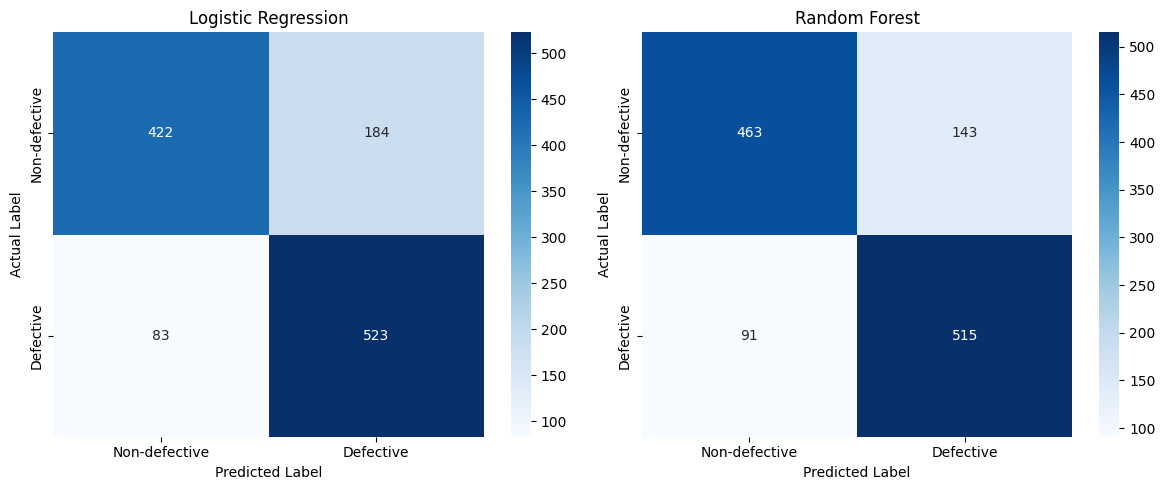

In [8]:
# Compare the types of correct and incorrect predictions for both models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-defective", "Defective"],
        yticklabels=["Non-defective", "Defective"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

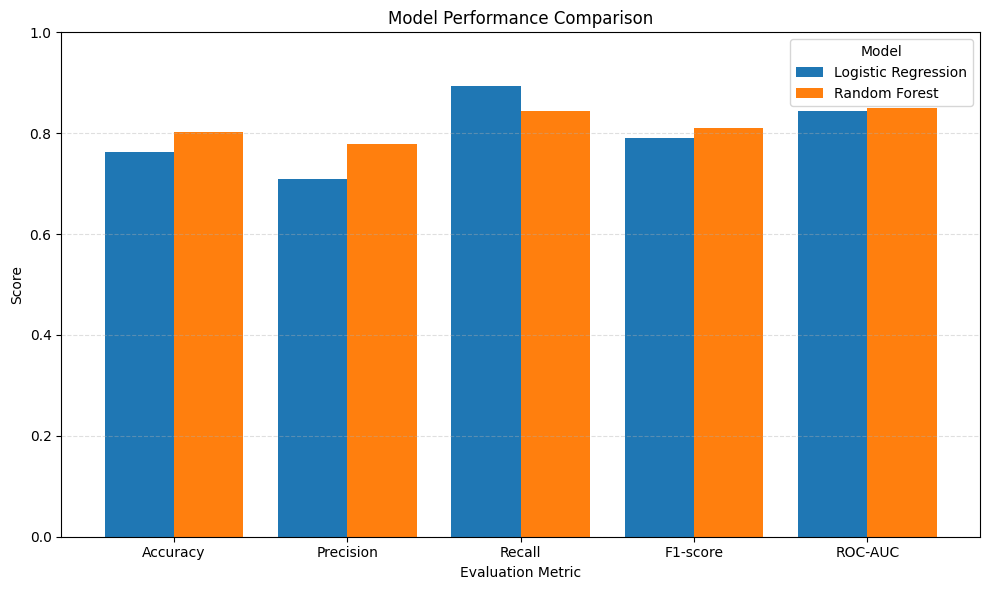

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a comparison table
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Logistic Regression": [0.7632, 0.7085, 0.8944, 0.7907, 0.8441],
    "Random Forest": [0.8020, 0.7790, 0.8432, 0.8098, 0.8504]
})

# Reshape data for plotting
plot_data = results.set_index("Metric")

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0,
    width=0.8
)

plt.title("Model Performance Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.legend(title="Model")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

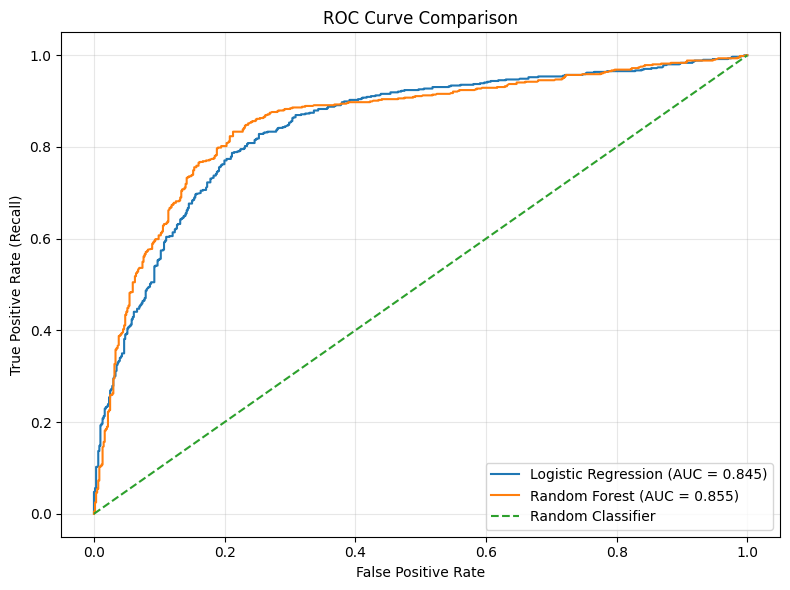

In [10]:
# Plot ROC curves using the predicted probabilities from each model
plt.figure(figsize=(8, 6))

for model_name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

# The diagonal represents random classification performance
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()